# 01 – Eksploracja danych PSE: zapotrzebowanie na moc w KSE

Cel: sprawdzić, jak wyglądają dane z API PSE (`kse-load`) dla jednej doby,
zanim pobierzemy dłuższy okres do modelu prognozy godzinowej.

Źródło: https://api.raporty.pse.pl/api/kse-load (bez klucza API, dane od 14.06.2024)

In [1]:
import requests
import pandas as pd

In [2]:
url = "https://api.raporty.pse.pl/api/kse-load"
params = {"$filter": "business_date eq '2026-10-23'"}  # jeden dzień

response = requests.get(url, params=params, timeout=30)
print(response.status_code)  # 200 = OK

200


In [3]:
data = response.json()
df = pd.DataFrame(data["value"])  # wiersze są w kluczu "value"
print("Liczba wierszy:", len(df))
print("Następna strona?", data.get("nextLink"))  # None = wszystko w jednej odpowiedzi

Liczba wierszy: 96
Następna strona? None


In [4]:
df["dtime"] = pd.to_datetime(df["dtime"])  # tekst -> data i godzina
print(df.shape)
print(df.columns.tolist())
df.head()

(96, 9)
['dtime', 'period', 'dtime_utc', 'load_fcst', 'period_utc', 'load_actual', 'business_date', 'publication_ts', 'publication_ts_utc']


,dtime,period,dtime_utc,load_fcst,period_utc,load_actual,business_date,publication_ts,publication_ts_utc
0,2026-10-23 00:15:00,00:00 - 00:15,2026-10-22 22:15:00,17000.0,22:00 - 22:15,17073.438,2026-10-23,2026-10-24 03:05:06.330,2026-10-24 01:05:06.330
1,2026-10-23 00:30:00,00:15 - 00:30,2026-10-22 22:30:00,16800.0,22:15 - 22:30,17060.857,2026-10-23,2026-10-24 03:05:06.330,2026-10-24 01:05:06.330
2,2026-10-23 00:45:00,00:30 - 00:45,2026-10-22 22:45:00,16600.0,22:30 - 22:45,16722.246,2026-10-23,2026-10-24 03:05:06.330,2026-10-24 01:05:06.330
3,2026-10-23 01:00:00,00:45 - 01:00,2026-10-22 23:00:00,16450.0,22:45 - 23:00,16683.621,2026-10-23,2026-10-24 03:05:06.330,2026-10-24 01:05:06.330
4,2026-10-23 01:15:00,01:00 - 01:15,2026-10-22 23:15:00,16300.0,23:00 - 23:15,16562.498,2026-10-23,2026-10-24 03:05:06.330,2026-10-24 01:05:06.330


## Dane

Jedna doba = **96 wierszy** (rozdzielczość 15 minut) i 9 kolumn. Najważniejsze:

| Kolumna | Znaczenie |
|---|---|
| `dtime` | koniec 15-minutowego okresu, czas lokalny (00:15 = okres 00:00–00:15) |
| `dtime_utc` | to samo w UTC; tego używamy w modelu, bo nie psują go zmiany czasu |
| `load_actual` | rzeczywiste zapotrzebowanie na moc [MW], **zmienna docelowa** |
| `load_fcst` | prognoza PSE [MW], **benchmark** do pobicia |
| `business_date` | doba handlowa, której dotyczą dane |

Uwaga: w dniu zmiany czasu doba ma 92 lub 100 wierszy, dlatego czas liczymy w UTC.

Text(0.5, 1.0, 'Zapotrzebowanie KSE, 2026-10-23')

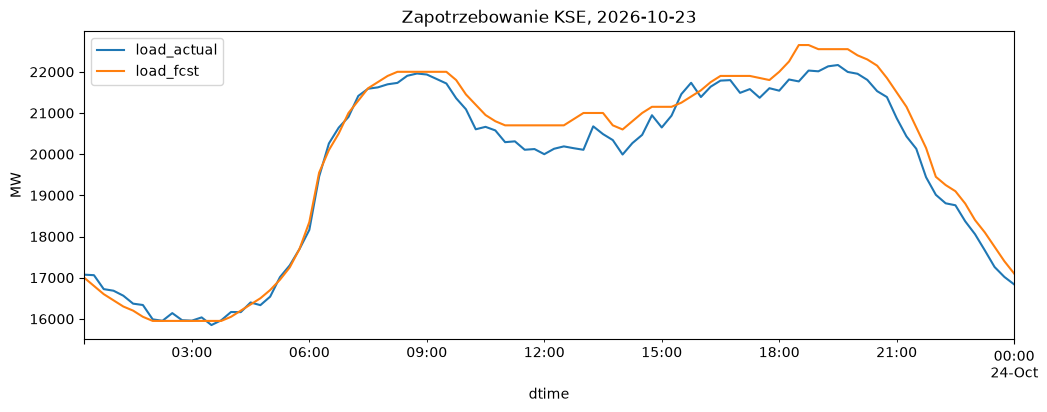

In [5]:
ax = df.plot(x="dtime", y=["load_actual", "load_fcst"], figsize=(12, 4))
ax.set_ylabel("MW")
ax.set_title("Zapotrzebowanie KSE, 2026-10-23")

## Obserwacje (23.10.2026)

- **Profil dobowy:** minimum w nocy (~16 000 MW, 2:00–4:00), gwałtowny wzrost
  między 5:00 a 8:00, dwa szczyty: poranny (~9:00) i wieczorny (~19:00–20:00, >22 000 MW).
- **Spadek w południe** (~20 000 MW, 11:00–14:00): prawdopodobnie efekt fotowoltaiki
  prosumenckiej, która obniża zapotrzebowanie widziane przez sieć.
  Wniosek: w modelu warto użyć nasłonecznienia i zachmurzenia z Open-Meteo.
- **Prognoza PSE:** bardzo dokładna w nocy i rano, po południu i wieczorem
  przeszacowuje o kilkaset MW.
- **Średni błąd prognozy PSE (MAE):** 318 MW, to wartość do pobicia przez nasz model.

Następny krok: pobrać wiele dni (funkcja `fetch_load` w `src/pse_client.py`).

In [6]:
blad = (df["load_fcst"] - df["load_actual"]).abs()
print("Średni błąd bezwzględny (MAE):", round(blad.mean()), "MW")

Średni błąd bezwzględny (MAE): 318 MW
